# Time Series: Advanced Assignment Part 3
## Deep Learning and time-series data analysis.

**Student Name(s):**

**Group No:**

In this assignment we will use a Tutorial available from [Kaggle](https://www.kaggle.com/code/amirrezaeian/time-series-data-analysis-using-lstm-tutorial/notebook). 
The aim is just to show how to build the simplest Long short-term memory (LSTM) recurrent neural network for the data.

In this part we have two advance exercises all other exercises are basic. 

### The Dataset
 The description of data can be found [here](http://archive.ics.uci.edu/ml/datasets/Individual+household+electric+power+consumption)

#### Attribute Information:

 1. date: Date in format dd/mm/yyyy   
 2. time: time in format hh:mm:ss   
 3. global_active_power: household global minute-averaged active power (in kilowatt)   
 4. global_reactive_power: household global minute-averaged reactive power (in kilowatt)   
 5. voltage: minute-averaged voltage (in volt)   
 6. global_intensity: household global minute-averaged current intensity (in ampere)   
 7. sub_metering_1: energy sub-metering No. 1 (in watt-hour of active energy). It corresponds to the kitchen, containing mainly a dishwasher, an oven and a microwave (hot plates are not electric but gas powered).   
 8. sub_metering_2: energy sub-metering No. 2 (in watt-hour of active energy). It corresponds to the laundry room, containing a washing-machine, a tumble-drier, a refrigerator and a light.   
 9. sub_metering_3: energy sub-metering No. 3 (in watt-hour of active energy). It corresponds to an electric water-heater and an air-conditioner.   

### Package Imports

In [20]:
# Let`s import all packages that we may need:
# Note that some package imports are different from the origional. 
import sys 
import numpy as np # linear algebra
from scipy.stats import randint
import pandas as pd # data processing
import matplotlib.pyplot as plt # this is used for the plot the graph 
import seaborn as sns # used for plot interactive graph. 
from sklearn.model_selection import train_test_split # to split the data into two parts
from sklearn.model_selection import KFold # use for cross validation
from sklearn.preprocessing import StandardScaler # for normalization
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline # pipeline making
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectFromModel
from sklearn import metrics # for the check the error and accuracy of the model
from sklearn.metrics import mean_squared_error,r2_score

Some package imports are different from the original worksheet ( due to changes introduced afterwards). If you get error revert back to original imports as given in the original notebook. 

In [21]:
## for Deep-learing:
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD 
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.python.keras  import utils
import itertools
from tensorflow.keras.layers import LSTM, Input
from keras.layers import Conv1D
from keras.layers import MaxPooling1D
from keras.layers import Dropout


### Importing the data and data processing
We import data and directly apply the following preprocessing:
1. Note that data include 'nan' and '?' as a string. Both are converted to numpy nan in importing stage (above) and treated both of them the same.  
2. Two columns 'Date' and 'Time' are merged to 'dt'.  
3. Covret the the data to time-series type by taking index to be the time.

In [22]:
# Importing data
df = pd.read_csv('household_power_consumption.txt', sep=';', 
                 parse_dates={'dt' : ['Date', 'Time']}, infer_datetime_format=True, 
                 low_memory=False, na_values=['nan','?'], index_col='dt')

/var/folders/45/82jzbv_s5pj342pnp3q6xmhh0000gn/T/ipykernel_73622/3886209577.py:2: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  df = pd.read_csv('household_power_consumption.txt', sep=';',
/var/folders/45/82jzbv_s5pj342pnp3q6xmhh0000gn/T/ipykernel_73622/3886209577.py:2: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv('household_power_consumption.txt', sep=';',
/var/folders/45/82jzbv_s5pj342pnp3q6xmhh0000gn/T/ipykernel_73622/3886209577.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv('household_

In [23]:
# Let's inspect the imported data
print("Shape is:", df.shape)
df.head()

Shape is: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dt,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [24]:
# And some basic statistics
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [25]:
df.columns

Index(['Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')

####  Dealing with missing values  'nan' with a test statistic
As we have observed, there were some "missing" or  ''nan'' values(both were replaced with nan at the time of import). One can impute the missing values with test statistics such as max, min, median, or mean. One can also apply more advanced imputation. We leave it as an advanced exercise to determine the best imputation strategy. For basic exercise, you can replace the nan with 'mean'. In the code below, write your code to replace nan with mean.

In [26]:
nan_check = df.isnull().sum()
nan_check

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [27]:
## finding all columns that have nan:

cols_with_nan = df.isna().any()
cols_with_nan_indices = np.where(cols_with_nan)[0]
cols_with_nan_indices

array([0, 1, 2, 3, 4, 5, 6])

In [28]:
# filling nan with mean in any columns

df = df.fillna(df.mean())
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dt,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [29]:
# another sanity check to make sure that there are not more any nan
# nan_check = df.isna().sum()
# nan_check

In [30]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.050655e+00,1.120142e-01,3.219643e+00,4.416490e+00,6.114397e+00,5.785470e+00,8.384178e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.100000e-01,4.800000e-02,2.390200e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.300000e-01,1.020000e-01,2.409600e+02,2.800000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.520000e+00,1.920000e-01,2.428600e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


#### Advance Exercise 
Apply other imputation strategies and compare them. 

In [39]:
# Your code for advance exercise. 
import time
import tensorflow as tf

def build_model():
    model = Sequential()
    model.add(Input(shape=(train_X.shape[1], train_X.shape[2])))
    model.add(LSTM(150))
    model.add(Dropout(0.15))
    model.add(Dense(1))
    model.compile(loss="mae", optimizer="adam")
    return model

def test_rmse(model):
    predict = model.predict(test_X, verbose=0)
    testX2 = test_X.reshape((test_X.shape[0], 7))
    inv_predicted = scaler.inverse_transform(np.concatenate((predict, testX2[:, 1:]), axis=1))[:, 0]
    inv_y = scaler.inverse_transform(np.concatenate((test_y.reshape(-1, 1), testX2[:, 1:]), axis=1))[:, 0]
    return np.sqrt(mean_squared_error(inv_y, inv_predicted))

results, models = [], {}
for batch_size in [16, 32, 50, 72, 128]: ## different batch size
    tf.keras.utils.set_random_seed(0)
    model = build_model()
    stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    t0 = time.time()
    history = model.fit(train_X, train_y, epochs=100, batch_size=batch_size,
                        validation_split=0.2, callbacks=[stop], verbose=0)
    val_loss = history.history['val_loss']
    results.append({'batch_size': batch_size,
                    'best_epoch': int(np.argmin(val_loss)) + 1,
                    'val_loss': np.min(val_loss),
                    'time (s)': time.time() - t0})
    models[batch_size] = model

results = pd.DataFrame(results).sort_values('val_loss')
display(results.round(4))

best_batch = int(results.iloc[0]['batch_size'])
print('Best batch size: %d, test RMSE: %.3f' % (best_batch, test_rmse(models[best_batch])))



,batch_size,best_epoch,val_loss,time (s)
4,128,24,0.0077,4.8174
1,32,12,0.0077,7.6193
3,72,22,0.0078,6.9395
2,50,9,0.0079,4.8971
0,16,13,0.0080,9.2888


Best batch size: 128, test RMSE: 0.264


### Machine-Leaning: LSTM Data Preparation and feature engineering
We will apply recurrent nueral network (LSTM) which is best suited for time-seriers and sequential problem. This approach is the best if we have large data.  

We will frame the supervised learning problem as predicting the Global_active_power at the current time (t) given the Global_active_power measurement and other features at the prior time step.

In [32]:
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	n_vars = 1 if type(data) is list else data.shape[1]
	dff = pd.DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(dff.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(dff.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = pd.concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg 

* In order to reduce the computation time, and also get a quick result to test the model.  One can resmaple the data over hour (the original data are given in minutes). This will reduce the size of data from 2075259 to 34589 but keep the overall strucure of data as shown in the above.   

In [33]:
shape_before = df.shape
print("Shape before: " ,shape_before)
# .resample('h').mean()
df_resample = df
print("Shape after: ", df_resample.shape)
df_resample.head()


Shape before:  (2075259, 7)
Shape after:  (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dt,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Note: Scale all features in range of [0,1]. 

Show 7 input variables (input series) and the 1 output variable for 'Global_active_power' at the current  time in hour (depending on resampling).

In [34]:
values = df_resample.values
values = values.astype('float32')


scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(values)

reframed = series_to_supervised(scaled, 1, 1)
reframed.drop(reframed.columns[[8, 9, 10, 11, 12, 13]], axis=1, inplace=True)
print(reframed.head())

   var1(t-1)  var2(t-1)  var3(t-1)  var4(t-1)  var5(t-1)  var6(t-1)  \
1   0.374796   0.300719   0.376091   0.377593        0.0     0.0125   
2   0.478363   0.313669   0.336995   0.473029        0.0     0.0125   
3   0.479631   0.358273   0.326009   0.473029        0.0     0.0250   
4   0.480898   0.361151   0.340549   0.473029        0.0     0.0125   
5   0.325005   0.379856   0.403231   0.323651        0.0     0.0125   

   var7(t-1)   var1(t)  
1   0.548387  0.478363  
2   0.516129  0.479631  
3   0.548387  0.480898  
4   0.548387  0.325005  
5   0.548387  0.311787  


### Splitting the rest of data to train and validation sets

First, split the prepared dataset into train and test sets. To speed up the training of the model (for the sake of the demonstration), we will only train the model on the first year of data, then evaluate it on the next 3 years of data.

In [35]:
n_train_time = 24 * 365 ## 1 year of data
values = reframed.values

train = values[:n_train_time, :]
test = values[n_train_time:, :]

train_X, train_y = train[:, :-1], train[:, -1]
test_X, test_y = test[:, :-1], test[:, -1]
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1]))
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))

print(train_X.shape, train_y.shape, test_X.shape, test_y.shape) 


(8760, 1, 7) (8760,) (2066498, 1, 7) (2066498,)


In [36]:
# split into train and test sets

##test = values[n_train_time:n_test_time, :]
# split into input and outputs

# reshape input to be 3D [samples, timesteps, features]

print(train_X.shape, train_y.shape, test_X.shape, test_y.shape) 
# We reshaped the input into the 3D format as expected by 
# LSTMs, namely [samples, timesteps, features].

(8760, 1, 7) (8760,) (2066498, 1, 7) (2066498,)


#### Model architecture

1.  LSTM with 150 neurons in the first visible layer  
2. dropout 15%  
3. 1 neuron in the output layer for predicting Global_active_power.  
4. The input shape will be 1 time step with 7 features.  
5. Use the Mean Absolute Error (MAE) loss function and the efficient Adam version of stochastic gradient descent.  
6. The model will be fit for 30 training epochs with a batch size of 50.  

Epoch 1/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0449 - val_loss: 0.0117
Epoch 2/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0213 - val_loss: 0.0094
Epoch 3/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0197 - val_loss: 0.0092
Epoch 4/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0195 - val_loss: 0.0101
Epoch 5/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0190 - val_loss: 0.0079
Epoch 6/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0187 - val_loss: 0.0087
Epoch 7/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0188 - val_loss: 0.0088
Epoch 8/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0184 - val_loss: 0.0079
Epoch 9/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0185 - val_loss: 0.0087
Epoch 10/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0185 - val_loss: 0.0082
Epoch 11/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0182 - val_loss: 0.0081
Epoch 12/30
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

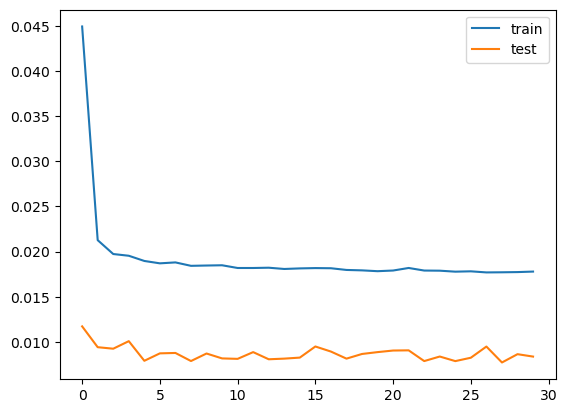

64579/64579 ━━━━━━━━━━━━━━━━━━━━ 22s 344us/step


In [37]:
# here your code

#    model.add(LSTM(70))
#    model.add(Dropout(0.3))
model = Sequential()
model.add(Input(shape=(train_X.shape[1], train_X.shape[2])))
model.add(LSTM(150))
model.add(Dropout(0.15))
model.add(Dense(1))
model.compile(loss="mae", optimizer="adam")

history = model.fit(train_X, train_y, epochs=30, batch_size=50, validation_split=0.2)

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

predict = model.predict(test_X)



In [38]:
print(predict.shape)
testX2 = test_X.reshape((test_X.shape[0], 7))

inv_predicted = np.concatenate((predict, testX2[:, 1:]), axis=1)
inv_predicted = scaler.inverse_transform(inv_predicted)[:, 0]
print(inv_predicted.shape)

test_y2 = test_y.reshape((len(test_y), 1))
inv_y = np.concatenate((test_y2, testX2[:, 1:]), axis=1)
inv_y = scaler.inverse_transform(inv_y)[:, 0]
print(inv_y.shape)

rmse = np.sqrt(mean_squared_error(inv_y, inv_predicted))
print('Test RMSE: %.3f' % rmse)


(2066498, 1)
(2066498,)
(2066498,)
Test RMSE: 0.265


#### Advanced Exercise

To improve the model, one has to adjust epochs and batch_size. Find optimal values of the epoch and batch_size. 

In [40]:
# Your code here. 

epoch_values = [10, 20, 30]
batch_values = [32, 50, 64]
results = []

for epochs in epoch_values:
    for batch_size in batch_values:
        tf.keras.backend.clear_session()
        candidate = Sequential([LSTM(150, input_shape=(train_X.shape[1], train_X.shape[2])), Dropout(0.15), Dense(1)])
        candidate.compile(loss="mae", optimizer="adam")

        sample_history = candidate.fit(train_X, train_y, epochs=epochs, batch_size=batch_size, validation_split=0.20, shuffle=False, verbose=0)
        results.append({
            "epochs": epochs,
            "batch_size": batch_size,
            "validation_mae": min(sample_history.history["val_loss"])
        })

results_df = (pd.DataFrame(results).sort_values("validation_mae").reset_index(drop=True))
display(results_df)

best_epochs = int(results_df.loc[0, "epochs"])
best_batch_size = int(results_df.loc[0, "batch_size"])
print(f"best epochs: {best_epochs}\nbest batch_size: {best_batch_size}")

/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,epochs,batch_size,validation_mae
0,30,50,0.008094
1,20,50,0.008682
2,20,64,0.008763
3,30,64,0.008781
4,10,64,0.008821
5,10,50,0.010140
6,20,32,0.010756
7,30,32,0.010812
8,10,32,0.012526


best epochs: 30
best batch_size: 50
